# Informal summer report

**Short summary:**
Throughout the summer of 2025, I worked on extending my project from the Spring 2025 quarter of CS 221. The original project involved reproducing MAB bandit simulation results, and basic proofs for some well-known regret bound results.

In the following sections, I detail the extension of the project in various aspects, especially with regards to the paper [Aligning AI Agents via Information-Directed Sampling](https://arxiv.org/pdf/2410.14807). I describe major improvements in simulation development, a minor theoretical improvement following a reasonable assumption, and ideas for potential future directions inspired by simulation insights.

**TOPICS:**
- Simulator improvements
- Insights from simulations
- Small theoretical improvement
- Potential future work


## Simulator improvements

**Summary:**
Integrated a bunch of best-practices for Python software. Focused on making simulations easily reproducible, while preparing for additional extensions in terms of new algorithms, new bandit settings, new result analysis. Additionally, integrated a few things for performance and future distributed work.

- Added command-line args.
- Added better parallelism and integration with [Ray](https://www.ray.io/) multiprocessing.
    > This can eventually make it easy to extend to distributing work across a cluster.
- Added [typing](https://mypy-lang.org/), [uv integration](https://docs.astral.sh/uv/), [linting](https://docs.astral.sh/ruff/), precommits, and cleaned up the code.
- Added ai-alignment bandit setting and algorithms.
- Added numpy [Random Generator](https://numpy.org/doc/2.3/reference/random/generator.html) for reproducible results.
- Added run configuration saving using [Pydantic](https://docs.pydantic.dev/latest/).
- Added better result saving with [Polars](https://pola.rs/).

## Insights from simulations

Human actions:
- Number of human actions over time:
- IDS --> number of human actions is relatively similar across all arms

When using arg-min:
- Information ratio tends to be much larger.
- IDS but only arg-min tends to choose human actions much less frequently.
- Hypothesis: with normal IDS, even when regret for a human action is known to be high, we will still choose a policy that sometimes picks the human action over an environment action, rather than waiting for environment actions to be chosen enough such that the information gained is so small such that we finally decide to choose a human action.

Info ratio:
- IDS info ratio seems to be bounded(?) by a constant? Don't know how to confirm this.

Pure proxy TS policy:
- (TS ep1) Slope of regret of time-varying epsilon policy seems to actually have sqrt dependency on T.
- (TS ep2) Slope of regret of fixed epsilon policy seems to be steeper, yet always lower than above policy.



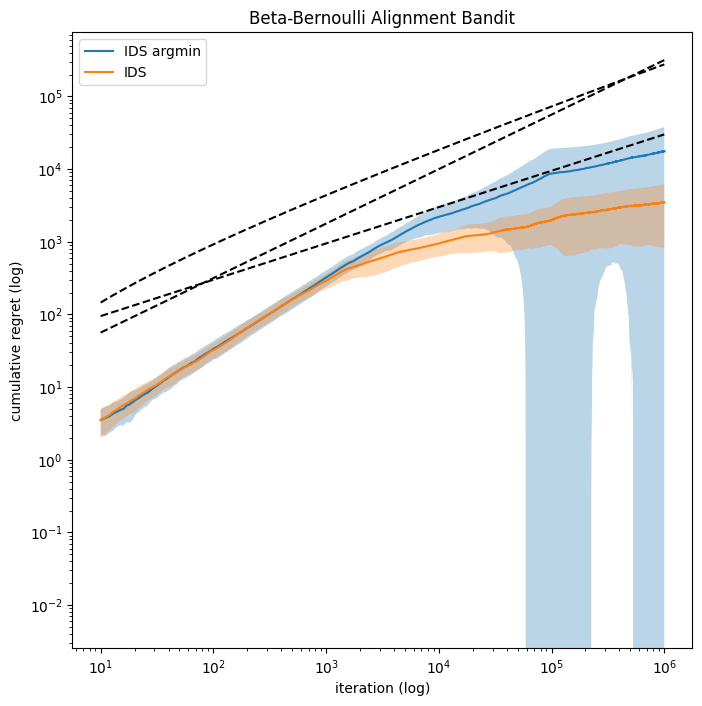

In [1]:
from IPython.display import Image

Image(filename="ids-argmin-vs-ids-log.png")

Info ratios of argmin IDS vs IDS:

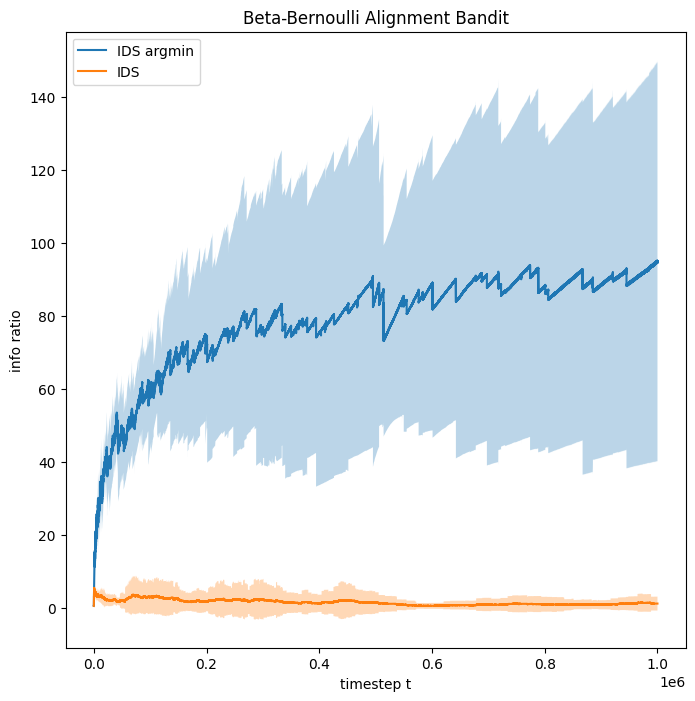

In [2]:
Image(filename="ids-argmin-vs-ids-info-ratio.png")

Cumulative human actions from argmin IDS vs IDS:

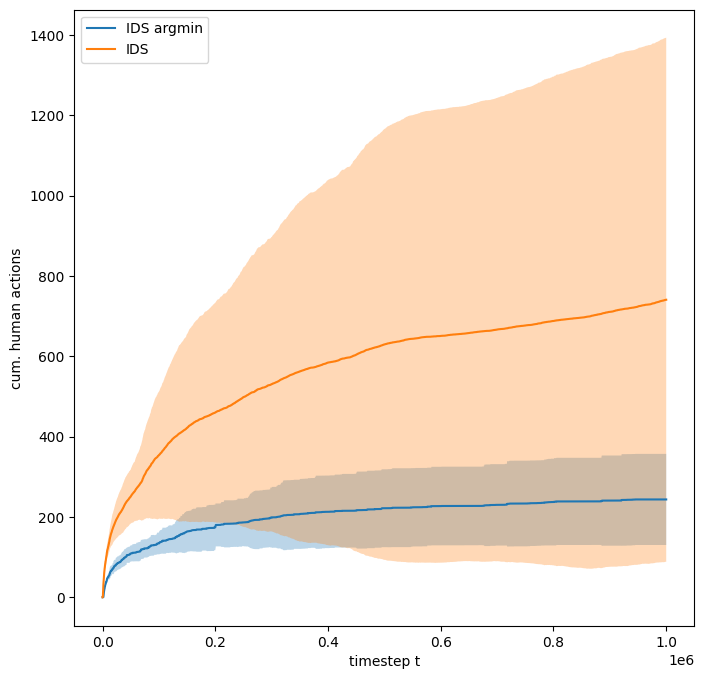

In [3]:
Image(filename="ids-argmin-vs-ids-human-actions.png")

Regret plot of pure TS with epsilons:

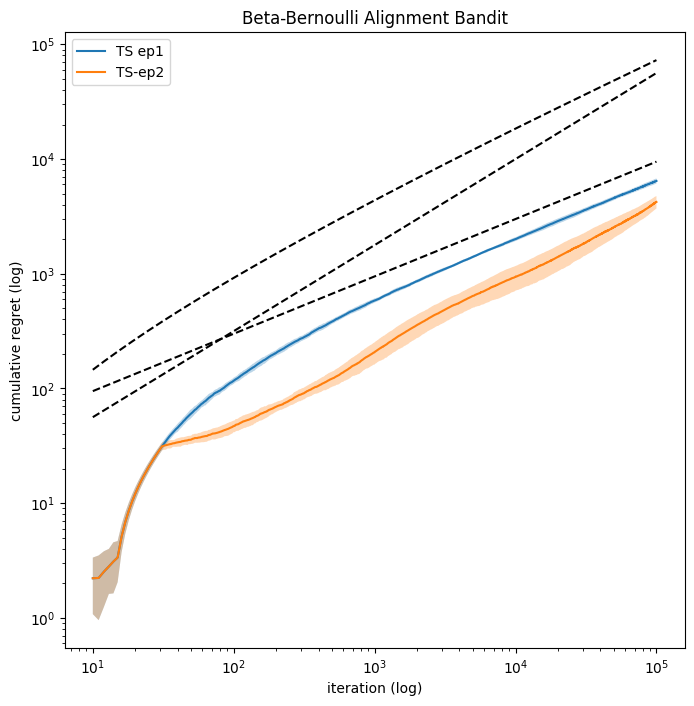

In [4]:
Image(filename="ts1-vs-ts2-log.png")

## Small theoretical improvement

**Directions explored:**
- Trying to directly bound IDS instead of using proxy policy.
    - Needed to figure out a bound on the number of human actions, couldn't figure out a good bound for this.
    - Info ratio of an individual human action is very easy (just increases with number of pulls).
    - However, since IDS minimizes based on info ratio of policies and not individual actions, I didn't know how to progress with that.
- Playing around with inequalities in Lemma 15 and 17 to try to get a tighter bound.
    - Not very fruitful after a few days of fiddling around.
- Time-step dependent epsilon:
    - I let e = e_t, and then tried to see if I could find an good candidate sequence for e_t such that it led to a better result.
    - It (kind of) worked, which led to the simplified idea:
- e = (|A|/T)^(1/3).
    - This gave an improved bound under the condition that T > |A|, which can be a reasonable assumption sometimes.
    - Improved bound is O(|A|^(5/6) T^(2/3)), compared to O(|A|^(3/4) T^(3/4)).

## Potential future work + questions
- Continue working on simulator.
- Extend to settings other than Bernoulli.
- Continue to work on pushing the regret bound down.

Questions:
- What was the idea behind using the proxy policy? Was it because it is just easier to work with theoretically since we can use probability matching of TS?
- Are there examples of trying to directly analyze IDS without relying on other algorithms like TS?
- Specific proof step (b) in Lemma 15.
